In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [9]:
import os

folders = os.listdir("/content/drive/MyDrive")

for folder in folders:
    if "SkillMe" in folder:
        print("Folder Name:", repr(folder))

Folder Name: 'SkillMe_Projects '


In [13]:
import os

project_path = "/content/drive/MyDrive/SkillMe_Projects "

print(os.path.exists(project_path))

os.chdir(project_path)

print("Project Folder Connected Successfully!")
print(os.getcwd())

True
Project Folder Connected Successfully!
/content/drive/MyDrive/SkillMe_Projects 


In [14]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

In [15]:
digits = load_digits()

print("Dataset loaded successfully!")
print("Images Shape:", digits.images.shape)
print("Data Shape:", digits.data.shape)
print("Target Shape:", digits.target.shape)

Dataset loaded successfully!
Images Shape: (1797, 8, 8)
Data Shape: (1797, 64)
Target Shape: (1797,)


In [16]:
print("First 10 Labels:")
print(digits.target[:10])

First 10 Labels:
[0 1 2 3 4 5 6 7 8 9]


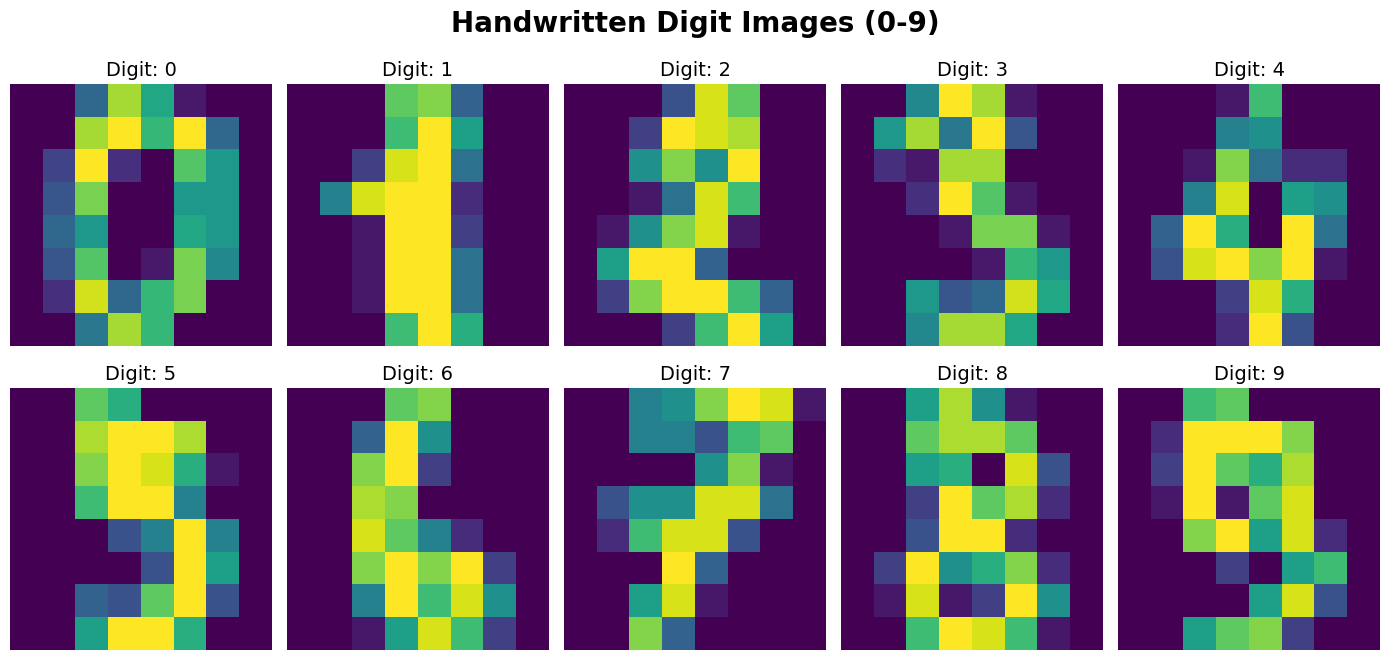

In [18]:
plt.figure(figsize=(14, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(digits.images[i], cmap='viridis')

    plt.title(f"Digit: {digits.target[i]}", fontsize=14)
    plt.axis('off')

plt.suptitle("Handwritten Digit Images (0-9)",
             fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

# Features (X) and Labels (y)
X = digits.data
y = digits.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (1437, 64)
Testing Data Shape: (360, 64)
Training Labels Shape: (1437,)
Testing Labels Shape: (360,)


In [20]:
from sklearn.neighbors import KNeighborsClassifier

In [21]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=3)

# Train the model
knn.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [22]:
# Predict test data
y_pred = knn.predict(X_test)

# Calculate accuracy
accuracy = knn.score(X_test, y_test)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.33333333333333 %


In [23]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 9]

results = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    results.append(accuracy * 100)

    print(f"K = {k}, Accuracy = {accuracy * 100:.2f}%")

K = 1, Accuracy = 97.78%
K = 3, Accuracy = 98.33%
K = 5, Accuracy = 98.61%
K = 9, Accuracy = 98.06%


In [24]:
import pandas as pd

comparison = pd.DataFrame({
    'K Value': k_values,
    'Accuracy (%)': results
})

print(comparison)

   K Value  Accuracy (%)
0        1     97.777778
1        3     98.333333
2        5     98.611111
3        9     98.055556


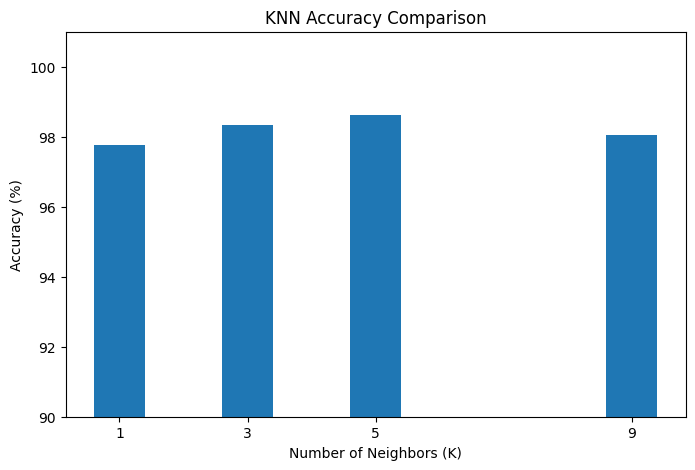

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(k_values, results)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy (%)")

plt.title("KNN Accuracy Comparison")

plt.xticks(k_values)
plt.ylim(90, 101)

plt.show()

In [26]:
# Create best KNN model
best_model = KNeighborsClassifier(n_neighbors=5)

# Train model
best_model.fit(X_train, y_train)

# Predict test images
y_pred = best_model.predict(X_test)

print("Best KNN Model Trained Successfully!")

Best KNN Model Trained Successfully!


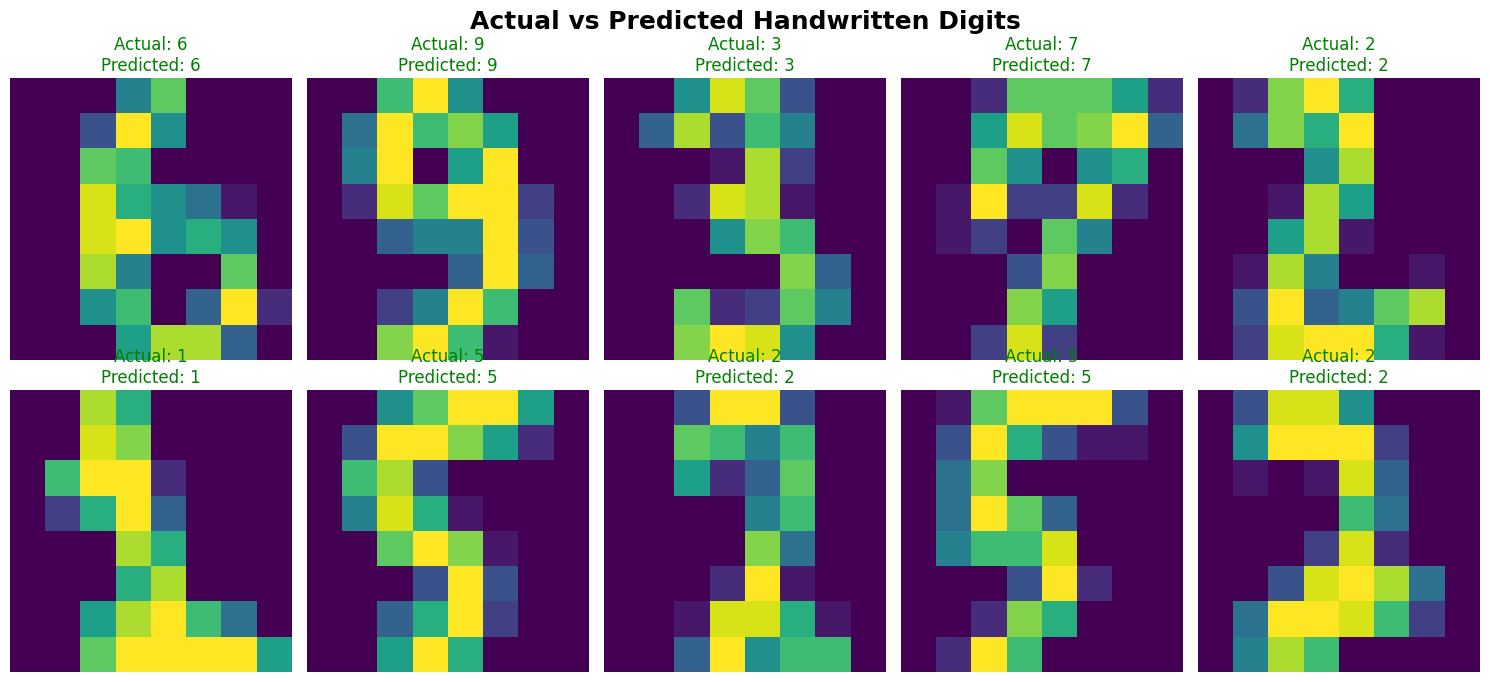

In [27]:
plt.figure(figsize=(15, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(8, 8)

    plt.imshow(image, cmap='viridis')

    actual = y_test[i]
    predicted = y_pred[i]

    if actual == predicted:
        color = 'green'
    else:
        color = 'red'

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=12
    )

    plt.axis('off')

plt.suptitle(
    "Actual vs Predicted Handwritten Digits",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate final accuracy
final_accuracy = accuracy_score(y_test, y_pred)

print("Final Model Accuracy:", round(final_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Final Model Accuracy: 98.61 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        34
           4       0.98      1.00      0.99        46
           5       0.98      0.96      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       1.00      1.00      1.00        30
           9       0.95      0.95      0.95        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [29]:
readme_content = """
# Handwritten Digit Classifier

## Project Overview
This project identifies handwritten digits (0-9)
using Machine Learning and the K-Nearest Neighbors
(KNN) algorithm.

## Dataset
- Dataset: Scikit-learn Digits Dataset
- Total Images: 1797
- Image Size: 8x8 pixels
- Classes: 0 to 9

## Technologies Used
- Python
- NumPy
- Matplotlib
- Pandas
- Scikit-learn
- Google Colab

## Machine Learning Algorithm
K-Nearest Neighbors (KNN)

## Train-Test Split
- Training Data: 80%
- Testing Data: 20%

## K Value Comparison

| K Value | Accuracy |
|---------|----------|
| 1 | 97.78% |
| 3 | 98.33% |
| 5 | 98.61% |
| 9 | 98.06% |

## Best Model
KNN with K = 5

## Final Accuracy
98.61%

## Conclusion
The model successfully classifies handwritten
digits with 98.61% test accuracy.
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!
